# Step 2 - Embedding: a text becomes a point

An embedding model reads a text and returns a list of numbers: a **vector**. Texts that mean similar
things get similar vectors. This is what makes retrieval possible: the question becomes a vector too,
and we look for the chunks that sit close to it.

We start with three everyday things, then move to our documents.

In [1]:
import os
import warnings

# Keep the output clean: no progress bars and no notices while the model loads.
os.environ["HF_HUB_VERBOSITY"] = "error"
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
os.environ["TRANSFORMERS_VERBOSITY"] = "error"
warnings.filterwarnings("ignore", message="IProgress not found")

In [2]:
from collections.abc import Sequence

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Patch

from src.chunking import Chunk, chunk_document, load_tokenizer
from src.config import load_config, project_path
from src.embedding import BgeM3Embedder
from src.parsing import load_corpus

config = load_config()
embedder = BgeM3Embedder(config.embedding)  # the first run downloads the model, about 2.3 GB

INK, MUTED, GRID, SURFACE = "#0b0b0b", "#898781", "#e1e0d9", "#fcfcfb"
BLUE, ORANGE = "#2a78d6", "#eb6834"
plt.rcParams.update(
    {"figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "text.color": INK, "font.size": 10}
)

## A text becomes 1024 numbers

In [3]:
vectors = embedder.embed(["un cane", "una macchina"]).dense
print("shape:", vectors.shape)
print("un cane      ->", vectors[0][:6].round(3), "...")
print("una macchina ->", vectors[1][:6].round(3), "...")

shape: (2, 1024)
un cane      -> [-0.005  0.04  -0.057 -0.015 -0.013 -0.002] ...
una macchina -> [-0.029  0.013 -0.079  0.019 -0.01  -0.001] ...


Two texts, 1024 numbers each. Nobody can read them and nobody can draw 1024 axes.

What we can do is look at their **shadow on a sheet of paper**. To decide how to hold the sheet we take
eight everyday things, four animals and four vehicles, and keep the two directions along which they differ
the most. A shadow flattens the other 1022 directions: distances on the sheet are only an impression,
the real measure comes later.

In [4]:
ANIMALS = ["un cane", "un cavallo", "un lupo", "un coniglio"]
VEHICLES = ["una macchina", "una moto", "un treno", "un camion"]

reference = embedder.embed(ANIMALS + VEHICLES).dense
center = reference.mean(axis=0)
directions = np.linalg.svd(reference - center, full_matrices=False)[2][:2]
X_LIMIT, Y_LIMIT = np.abs((reference - center) @ directions.T).max(axis=0) * 1.4


def shadow(texts: Sequence[str]) -> np.ndarray:
    """Embed the texts and return their position on the sheet."""
    return (embedder.embed(texts).dense - center) @ directions.T


def draw(title: str, known: Sequence[str], new: Sequence[str] = (), others: Sequence[str] = ()) -> None:
    """Draw texts on the sheet: known ones in blue, new ones in orange, the others in grey."""
    figure, axis = plt.subplots(figsize=(8, 4.2))
    groups = [(others, MUTED, "o", 40), (known, BLUE, "o", 110), (new, ORANGE, "D", 110)]
    for texts, color, marker, size in groups:
        if not texts:
            continue
        points = shadow(texts)
        axis.scatter(points[:, 0], points[:, 1], color=color, marker=marker, s=size, zorder=3)
        for index, (text, point) in enumerate(zip(texts, points, strict=True)):
            above = color != ORANGE and index % 2 == 0  # labels alternate so that neighbours do not overlap
            axis.annotate(
                text, point, xytext=(0, 10 if above else -18), textcoords="offset points", ha="center",
                color=MUTED if color == MUTED else INK, fontweight="normal" if color == MUTED else "bold",
            )
    axis.set_xlim(-X_LIMIT, X_LIMIT)
    axis.set_ylim(-Y_LIMIT, Y_LIMIT)
    axis.set_xticks([])
    axis.set_yticks([])
    for spine in axis.spines.values():
        spine.set_color(GRID)
    axis.set_title(title, loc="left", fontweight="bold")
    plt.show()

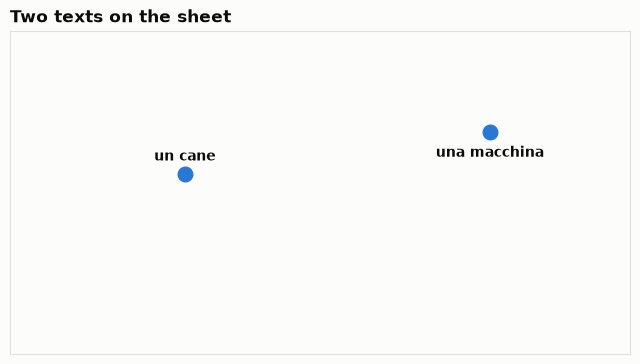

In [5]:
draw("Two texts on the sheet", known=["un cane", "una macchina"])

The dog and the car are far apart. Now a third text, one that the sheet has never seen: **un gatto**.
Where will it land?

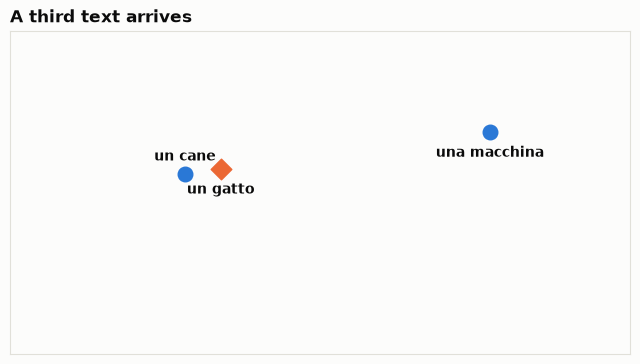

In [6]:
draw("A third text arrives", known=["un cane", "una macchina"], new=["un gatto"])

Right next to the dog, far from the car. Nobody told the model that cats and dogs are both animals:
it learned it by reading a very large amount of text.

It is not a coincidence of these three. Here are the other things we used to hold the sheet:

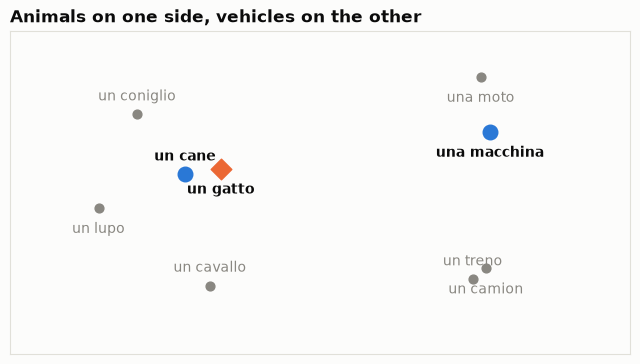

In [7]:
shown = ["un cane", "una macchina"]
rest = [text for text in ANIMALS + VEHICLES if text not in shown]
draw("Animals on one side, vehicles on the other", known=shown, new=["un gatto"], others=rest)

## How close? The cosine similarity

A drawing is an impression. The number used in practice is the **cosine** of the angle between two vectors:
1 when they point in the same direction, lower as they move apart.

In [8]:
def cosine(a: np.ndarray, b: np.ndarray) -> float:
    """Cosine of the angle between two vectors."""
    return float(a @ b / (np.linalg.norm(a) * np.linalg.norm(b)))


dog, car, cat = embedder.embed(["un cane", "una macchina", "un gatto"]).dense
print("un gatto - un cane:     ", round(cosine(cat, dog), 3))
print("un gatto - una macchina:", round(cosine(cat, car), 3))

un gatto - un cane:      0.827
un gatto - una macchina: 0.696


The same measure between the cat and all eight things of the sheet:

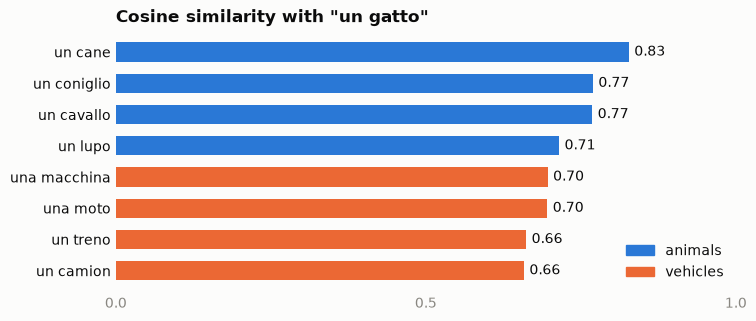

In [9]:
things = ANIMALS + VEHICLES
scores = np.array([cosine(cat, vector) for vector in embedder.embed(things).dense])
order = np.argsort(scores)[::-1]

figure, axis = plt.subplots(figsize=(8, 3.4))
colors = [BLUE if things[index] in ANIMALS else ORANGE for index in order]
bars = axis.barh([things[index] for index in order], scores[order], color=colors, height=0.62)
axis.bar_label(bars, fmt="%.2f", padding=4, color=INK)
legend = [Patch(color=BLUE, label="animals"), Patch(color=ORANGE, label="vehicles")]
axis.legend(handles=legend, frameon=False, loc="lower right")
axis.invert_yaxis()
axis.set_xlim(0, 1)
axis.set_xticks([0, 0.5, 1])
axis.tick_params(length=0, colors=INK)
axis.tick_params(axis="x", colors=MUTED)
axis.spines[:].set_visible(False)
axis.set_title('Cosine similarity with "un gatto"', loc="left", fontweight="bold")
plt.show()

Every animal is closer to the cat than every vehicle.

But look at the scale: a car has nothing to do with a cat, and it still gets 0.70. With this model even
unrelated texts score around 0.4. **A cosine is not a percentage**: it only means something next to
other cosines.

## A warning: one bare word is too little

The same three things, without the article.

In [10]:
dog, car, cat = embedder.embed(["cane", "macchina", "gatto"]).dense
print("gatto - cane:    ", round(cosine(cat, dog), 3))
print("gatto - macchina:", round(cosine(cat, car), 3))

gatto - cane:     0.559
gatto - macchina: 0.566


Now the cat is as close to the car as to the dog. The model was trained on sentences and passages:
a single word gives it almost nothing to work with, and the result cannot be trusted.

It is the same reason why in step 1 we refused chunks made of a title only:
**a text that is too short has a poor vector.**

## Our documents

Now the real thing: a question and seven chunks taken from different documents of the corpus.

In [11]:
documents = load_corpus(project_path(config.paths.parsed_dir))
tokenizer = load_tokenizer(config.embedding.model_name)
chunks = [chunk for document in documents for chunk in chunk_document(document, tokenizer, config.chunking)]


def find(source: str, section: str = "") -> Chunk:
    """First chunk whose source contains the given text and whose section starts with the given one."""
    return next(chunk for chunk in chunks if source in chunk.source and chunk.section.startswith(section))


examples = {
    "contract 017, Art. 7 - withdrawal": find("01_contratti/CTR-2024-017", "Art. 7"),
    "contract 017, Art. 3 - duration and renewal": find("01_contratti/CTR-2024-017", "Art. 3"),
    "contract 017, Art. 6 - penalties": find("01_contratti/CTR-2024-017", "Art. 6"),
    "contract 017, Art. 14 - governing law": find("01_contratti/CTR-2024-017", "Art. 14"),
    "an internal policy": find("06_policy_interne"),
    "a maintenance ticket": find("05_ticket_manutenzione"),
    "pump manual, alarm E-4012": find("03_manuali_tecnici", "E-4012"),
}
print(len(chunks), "chunks in the corpus,", len(examples), "picked as examples")

1754 chunks in the corpus, 7 picked as examples


question: Con quanto preavviso possiamo recedere dal contratto?


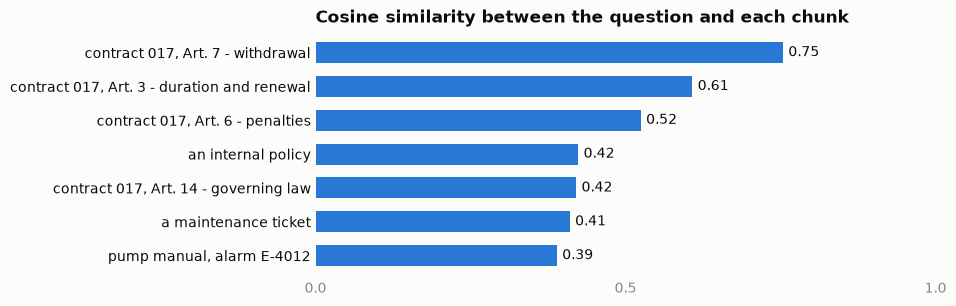

In [12]:
QUESTION = "Con quanto preavviso possiamo recedere dal contratto?"

question = embedder.embed([QUESTION]).dense[0]
scores = embedder.embed([chunk.text for chunk in examples.values()]).dense @ question
order = np.argsort(scores)[::-1]
labels = list(examples)

print("question:", QUESTION)
figure, axis = plt.subplots(figsize=(8, 3.2))
bars = axis.barh([labels[index] for index in order], scores[order], color=BLUE, height=0.62)
axis.bar_label(bars, fmt="%.2f", padding=4, color=INK)
axis.invert_yaxis()
axis.set_xlim(0, 1)
axis.set_xticks([0, 0.5, 1])
axis.tick_params(length=0, colors=INK)
axis.tick_params(axis="x", colors=MUTED)
axis.spines[:].set_visible(False)
axis.set_title("Cosine similarity between the question and each chunk", loc="left", fontweight="bold")
plt.show()

The article on withdrawal comes first. The article on duration and renewal is second: it talks about
notice too, the one needed to stop the renewal. Then the scores drop to about 0.4 for texts that have
nothing to do with the question, even when they come from the same contract.

This is retrieval in one line: turn the question into a vector, sort the chunks by cosine, keep the first few.

(The vectors of this model have length 1, so the cosine is simply the product `vectors @ question`.)

## The trap again: the same words in forty contracts

In step 1 we saw that Art. 7 is written with the same words in every contract. Here are the vectors of
Art. 7 in the three contracts with Beta Idroservizi, where the notice is 90, 60 and 30 days.

In [13]:
beta = [chunk for chunk in chunks if "01_contratti" in chunk.source and "_Beta_" in chunk.source]
beta = [chunk for chunk in beta if chunk.section == "Art. 7 - Recesso"]
names = [chunk.source.split("/")[1][:12] for chunk in beta]
vectors = embedder.embed([chunk.text for chunk in beta]).dense

print(" " * 14 + "  ".join(names))
for name, row in zip(names, vectors @ vectors.T, strict=True):
    print(name, "  ".join(f"{value:12.3f}" for value in row))

              CTR-2023-009  CTR-2024-017  CTR-2025-030
CTR-2023-009        1.000         0.987         0.965
CTR-2024-017        0.987         1.000         0.969
CTR-2025-030        0.965         0.969         1.000


0.97 and above: for the model these three chunks are the same text. They differ by one number, and a vector
that sums up a whole paragraph barely feels it.

So what happens when the question names the contract? We compare it with Art. 7 of all forty contracts.

In [14]:
NAMED_QUESTION = "Con quanto preavviso possiamo recedere dal contratto CTR-2024-017?"

contracts = [chunk for chunk in chunks if "01_contratti" in chunk.source]
article_7 = [chunk for chunk in contracts if chunk.section == "Art. 7 - Recesso"]
question = embedder.embed([NAMED_QUESTION]).dense[0]
scores = embedder.embed([chunk.text for chunk in article_7]).dense @ question
ranking = [article_7[index].source.split("/")[1][:12] for index in np.argsort(scores)[::-1]]

print("chunks compared:", len(article_7))
print("scores between", round(float(scores.min()), 3), "and", round(float(scores.max()), 3))
print("position of CTR-2024-017:", ranking.index("CTR-2024-017") + 1)

chunks compared: 40
scores between 0.608 and 0.62
position of CTR-2024-017: 19


All forty chunks get almost the same score and the right one is lost in the middle of the list.
Two reasons:

1. the text of the chunk never says which contract it belongs to (step 1);
2. a dense vector captures the meaning of a text, not an exact code such as `CTR-2024-017`.

## What we take away

- An embedding turns a text into a point. Texts with similar meaning are close, and the cosine says how close.
- A cosine is read next to other cosines, never alone.
- A text that is too short has a poor vector.
- Sorting the chunks by cosine already finds the right *article*. It does not find the right *contract*.

Two candidate fixes for the next step, retrieval:

1. write where a chunk comes from in the text that we embed, using `chunk.source` and `chunk.section`;
2. add an exact match on words and codes next to the dense vector. BGE-M3 already returns what is needed:
   the *sparse* weights, one for each word of the text.